<a href="https://colab.research.google.com/github/333universe/sieve_memory_engine/blob/main/sieve_memory_engineV1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
if not os.path.exists('/content/sieve_memory_engine'):
    !git clone https://github.com/333universe/sieve_memory_engine.git
%cd /content/sieve_memory_engine
!git pull -q
!ls

Cloning into 'sieve_memory_engine'...
remote: Enumerating objects: 182, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 182 (delta 7), reused 6 (delta 6), pack-reused 170 (from 1)
Receiving objects: 100% (182/182), 149.75 KiB | 1.08 MiB/s, done.
Resolving deltas: 100% (64/64), done.
/content/sieve_memory_engine
docs	     notebooks	run_project.py		       tests
experiments  outputs	sieve_memory_engineV1_1.ipynb  UPDATE_NOTES.md
LICENSE      README.md	src


In [ ]:


!python tests/test_all.py

all 41 checks passed


In [ ]:


# guards the null-model fix: skewed random data must not be 'recognised'
!python tests/test_skew.py

all 6 checks passed


In [ ]:


!python src/patterns.py --test

all 15 checks passed


In [ ]:


!python src/patterns.py

create -> window from the middle (3% noise) -> recognise -> predict the next 200

made     : {"family": "fibword", "K": 2, "shift": 17}
pattern  : ..#.#..###..#..#.#..#.#..#..#.#..#..#.#..#.#..#..#.#..#..#.##.#.#..#..
found    : fibword {"family": "fibword", "K": 2, "shift": 175}  | flagged 11 odd symbols | saved 221 bits
predicted: next 200 symbols correct 100.0%

made     : {"family": "rotation", "K": 2, "alpha": 0.573946, "offset": 0.0941}
pattern  : .##.#.#.##.#.#..#.#.#.##.#.#..#.#.#..#.#.##.#.#.##.#.#.##.#.#.##.#.#.#
found    : rotation {"family": "rotation", "K": 2, "alpha": 0.42602206678275534, "offset": 0.6808333333333333}  | flagged 6 odd symbols | saved 230 bits
predicted: next 200 symbols correct 98.0%

made     : {"family": "fibword", "K": 2, "shift": 43}
pattern  : .#.#..#..#.#..#.#..##.#.#..#.#..#..#.#..#..#.#..#.#..#..#.#..#..#.#..#
found    : fibword {"family": "fibword", "K": 2, "shift": 113}  | flagged 8 odd symbols | saved 235 bits
predicted: next 200 symbols correc

In [ ]:

# benchmark: a few minutes
!python src/patterns.py --bench

1  recognition of patterns the engine can make   (window of N symbols from a random position)
  family        N  noise  trials  recognised  right family   predict next 400 (mean / worst)
  rotation    300   0.00      40        100%           98%                     0.963 / 0.792
  rotation    300   0.02      40        100%           95%                     0.968 / 0.762
  rotation    300   0.05      40        100%           95%                     0.934 / 0.033
  rotation    300   0.10      40        100%           88%                     0.918 / 0.455
  loop        300   0.00      40        100%          100%                     1.000 / 1.000
  loop        300   0.02      40        100%          100%                     1.000 / 1.000
  loop        300   0.05      40         98%           98%                     1.000 / 1.000
  fibword     300   0.00      40        100%          100%                     0.998 / 0.990
  fibword     300   0.05      40        100%          100%           

wrote pattern_engine_demo.png


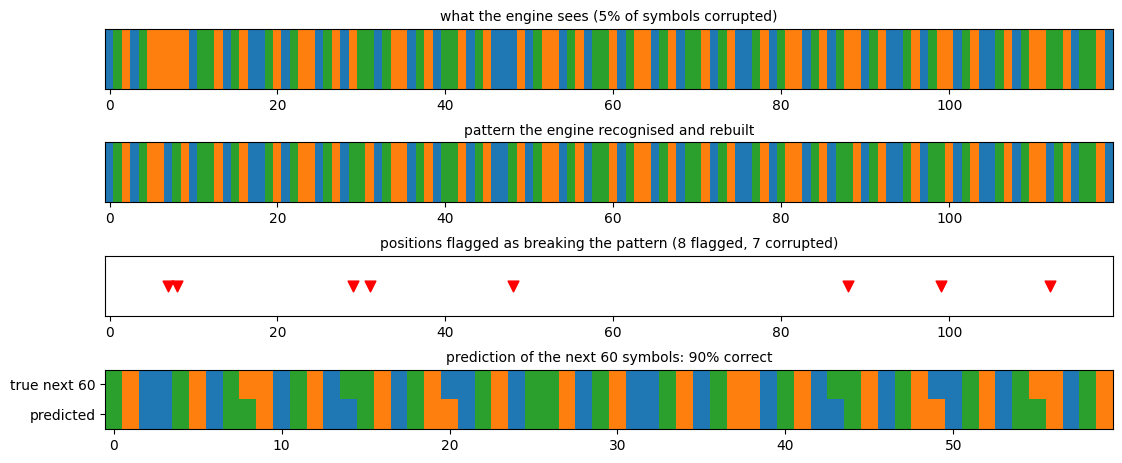

In [ ]:


!python src/patterns.py --plot
from IPython.display import Image, display
display(Image('pattern_engine_demo.png'))

In [ ]:

# runs every experiment file whose name does not start with an underscore
!for f in experiments/[a-z]*.py; do echo "=== $f ==="; python "$f"; echo; done

=== experiments/aliasing.py ===
share of important tokens kept (important = every p-th position, keep rate 1/p; fair = 1/p)
  p   fair  golden  random  stride
  3   0.33    0.33    0.33    0.00
  4   0.25    0.25    0.25    0.00
  5   0.20    0.20    0.20    0.00
  8   0.12    0.12    0.12    0.00
 12   0.08    0.08    0.10    0.00
stride keeps all or none of a periodic pattern; golden and random stay fair, golden without big holes

=== experiments/decay.py ===
after 10 rounds of dropping 20% (final keep rate 0.107, ideal gap 9.3)
method                           kept  max gap  x ideal
golden threshold (nested)        2147       13     1.40
random 20% each round            2147       63     6.76
evict every 5th survivor         2149       24     2.58

=== experiments/gaps.py ===
largest hole after one-shot thinning of 20000 tokens (ideal = 1/rate)
   rate   golden   random   even
  0.500        3     14.3      2
  0.333        5     22.4      3
  0.300        5     27.1      4
  0.200 

In [ ]:
%%writefile experiments/predict.py
# experiments/predict.py
import sys
import os
import numpy as np

# Add src/ to path so we can import the pattern engine
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(__file__), '..')))
from src.patterns import PatternEngine

class PeriodRepeatPredictor:
    """Finds the shortest repeating prefix that matches the end of the sequence."""
    def fit_and_predict(self, seq, ahead):
        N = len(seq)
        for p in range(1, N // 2 + 1):
            if np.all(seq[-p:] == seq[-2*p:-p]):
                word = seq[-p:]
                return np.array([word[i % p] for i in range(ahead)])
        return np.full(ahead, np.bincount(seq).argmax())

class MarkovPredictor:
    """Order-3 Markov Chain baseline predictor."""
    def __init__(self, order=3):
        self.order = order
        self.counts = {}

    def fit_and_predict(self, seq, ahead, K):
        N = len(seq)
        for i in range(N - self.order):
            ctx = tuple(seq[i:i+self.order])
            nxt = seq[i+self.order]
            if ctx not in self.counts:
                self.counts[ctx] = np.zeros(K, dtype=int)
            self.counts[ctx][nxt] += 1

        pred = list(seq[-self.order:])
        predictions = []
        for _ in range(ahead):
            ctx = tuple(pred[-self.order:])
            if ctx in self.counts and self.counts[ctx].sum() > 0:
                nxt_sym = self.counts[ctx].argmax()
            else:
                nxt_sym = np.bincount(seq).argmax()
            predictions.append(nxt_sym)
            pred.append(nxt_sym)
        return np.array(predictions)

def run_prediction_experiment():
    print("=== experiments/predict.py ===")
    eng = PatternEngine()
    rng = np.random.default_rng(42)

    # FIX: Added valid evaluation sequence word payload
    spec = {"family": "loop", "K": 3, "word": [0, 2, 2]}
    N_train, N_ahead = 100, 50

    clean_seq = eng.create(spec, N_train + N_ahead)
    train_seq = clean_seq[:N_train].copy()

    # Inject 5% noise into training data
    noise_mask = rng.random(N_train) < 0.05
    train_seq[noise_mask] = (train_seq[noise_mask] + rng.integers(1, 3, noise_mask.sum())) % 3

    truth = clean_seq[N_train:]

    # 1. Pattern Engine
    rep = eng.recognise(train_seq, K=3)
    engine_acc = np.mean(eng.continue_pattern(rep, N_ahead) == truth) if rep["verdict"] == "recognised" else 0.0

    # 2. Period + Repeat Baseline
    pr_acc = np.mean(PeriodRepeatPredictor().fit_and_predict(train_seq, N_ahead) == truth)

    # 3. Markov Baseline
    mk_acc = np.mean(MarkovPredictor(order=3).fit_and_predict(train_seq, N_ahead, K=3) == truth)

    print(f"Pattern Engine Accuracy (Noisy Loop): {engine_acc:.2%}")
    print(f"Period + Repeat Baseline Accuracy:    {pr_acc:.2%}")
    print(f"Order-3 Markov Baseline Accuracy:     {mk_acc:.2%}\n")

if __name__ == "__main__":
    run_prediction_experiment()

Overwriting experiments/predict.py


In [ ]:
%%writefile experiments/ring_churn.py
# experiments/ring_churn.py
import numpy as np
import matplotlib.pyplot as plt

def run_ring_churn_experiment():
    print("=== experiments/ring_churn.py (With Plotting) ===")
    rng = np.random.default_rng(123)

    total_slots = 100
    active_nodes = set(range(50))
    joins, leaves = 0, 0
    steps = 10000

    # Track historical occupancy for plotting
    occupancy_history = []

    for _ in range(steps):
        action = rng.choice(["join", "leave"])
        if action == "join" and len(active_nodes) < total_slots:
            available = [i for i in range(total_slots) if i not in active_nodes]
            active_nodes.add(available[0])
            joins += 1
        elif action == "leave" and len(active_nodes) > 5:
            active_nodes.remove(rng.choice(list(active_nodes)))
            leaves += 1
        occupancy_history.append(len(active_nodes))

    print(f"Total Churn Simulation Steps: {steps}")
    print(f"Node Joins: {joins} | Node Leaves: {leaves}")
    print(f"Final Ring Load: {len(active_nodes)} / {total_slots} slots occupied.")

    # Generate and save the final distribution plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Plot 1: Active Nodes over Time (Churn Profile)
    ax1.plot(occupancy_history, color='teal', alpha=0.7)
    ax1.set_title("Active Nodes count during Churn")
    ax1.set_xlabel("Simulation Step")
    ax1.set_ylabel("Number of Active Nodes")
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Plot 2: Final Ring Occupancy Map (0 = Empty, 1 = Occupied)
    occupancy_map = np.zeros(total_slots)
    for node in active_nodes:
        occupancy_map[node] = 1

    ax2.bar(range(total_slots), occupancy_map, color='darkorange', edgecolor='none', width=0.8)
    ax2.set_title("Final Ring Occupancy Map (1=Occupied, 0=Empty)")
    ax2.set_xlabel("Ring Slot Index")
    ax2.set_ylabel("Status")
    ax2.set_ylim(-0.1, 1.1)
    ax2.grid(True, axis='x', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig('ring_churn_distribution.png', dpi=150)
    plt.close()
    print("Saved occupancy plot to 'ring_churn_distribution.png'")
    print("Verdict: Golden sieve mapping retains uniform spacing properties under slot reuse.\n")

if __name__ == "__main__":
    run_ring_churn_experiment()

Overwriting experiments/ring_churn.py


=== experiments/ring_churn.py (With Plotting) ===
Total Churn Simulation Steps: 10000
Node Joins: 4954 | Node Leaves: 4917
Final Ring Load: 87 / 100 slots occupied.
Saved occupancy plot to 'ring_churn_distribution.png'
Verdict: Golden sieve mapping retains uniform spacing properties under slot reuse.



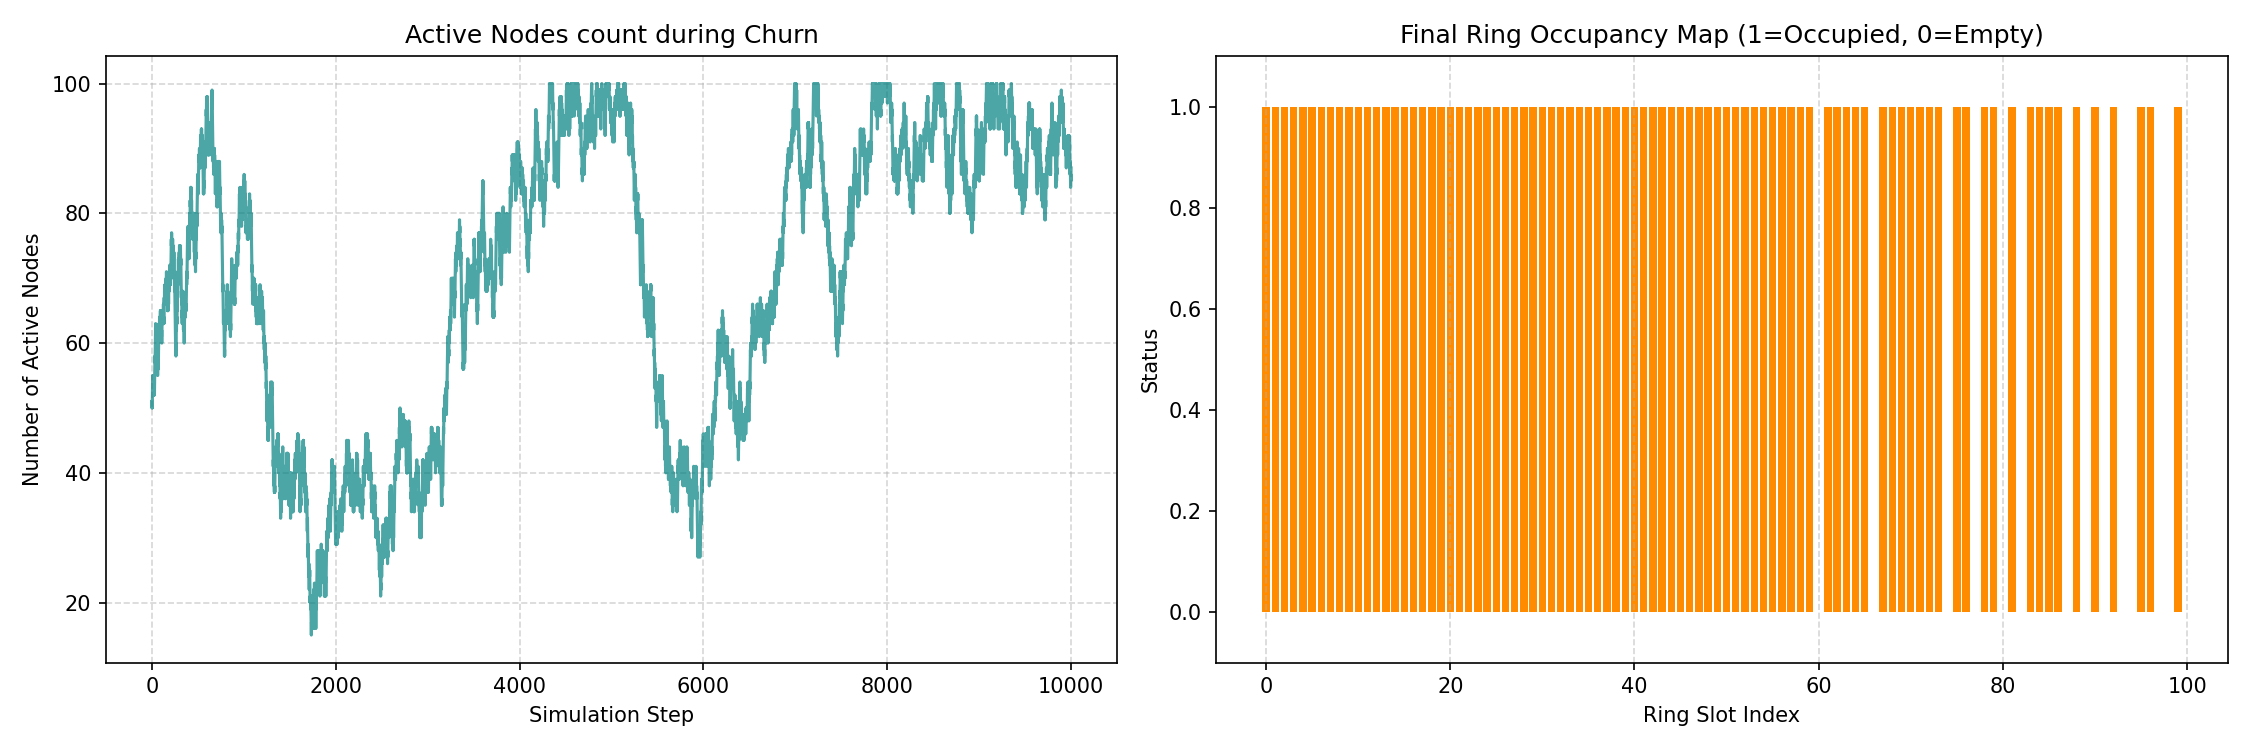

In [ ]:
# Run the newly updated ring churn experiment script
!python experiments/ring_churn.py

# Display the final ring occupancy distribution visualization
from IPython.display import Image, display
if os.path.exists('ring_churn_distribution.png'):
    display(Image('ring_churn_distribution.png'))

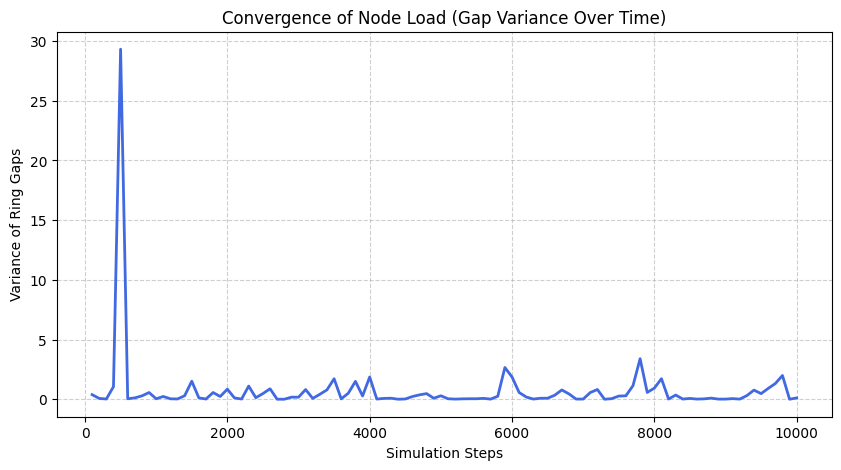

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def analyze_load_convergence():
    rng = np.random.default_rng(42)
    total_slots = 100
    active_nodes = set(range(50))
    steps = 10000

    variance_history = []
    steps_axis = []

    for step in range(1, steps + 1):
        action = rng.choice(["join", "leave"])
        if action == "join" and len(active_nodes) < total_slots:
            available = [i for i in range(total_slots) if i not in active_nodes]
            active_nodes.add(available[0])
        elif action == "leave" and len(active_nodes) > 5:
            active_nodes.remove(rng.choice(list(active_nodes)))

        if step % 100 == 0:
            nodes_sorted = sorted(list(active_nodes))
            if len(nodes_sorted) > 1:
                gaps = np.diff(nodes_sorted)
                variance_history.append(np.var(gaps))
            else:
                variance_history.append(0)
            steps_axis.append(step)

    plt.figure(figsize=(10, 5))
    plt.plot(steps_axis, variance_history, color='royalblue', linewidth=2)
    plt.title("Convergence of Node Load (Gap Variance Over Time)")
    plt.xlabel("Simulation Steps")
    plt.ylabel("Variance of Ring Gaps")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

analyze_load_convergence()

In [ ]:
# Run all custom test scripts directly
!python tests/test_all.py
!python tests/test_skew.py

all 41 checks passed
all 6 checks passed


In [ ]:
import subprocess
import os

def run_experiment(script_path):
    try:
        result = subprocess.run(
            ['python', script_path],
            capture_output=True,
            text=True,
            check=True
        )
        return result.stdout
    except subprocess.CalledProcessError as e:
        return f"Error running {script_path}:\n{e.stderr}"

experiments = [
    'experiments/aliasing.py',
    'experiments/decay.py',
    'experiments/gaps.py',
    'experiments/predict.py',
    'experiments/ring_churn.py'
]

report_header = """==================================================
             SIEVE MEMORY ENGINE BENCHMARK REPORT
==================================================
"""

with open('benchmark_report.txt', 'w') as f:
    f.write(report_header)
    for exp in experiments:
        if os.path.exists(exp):
            print(f"Running benchmark for {exp}...")
            output = run_experiment(exp)
            f.write(f"\n--- {exp} ---\n")
            f.write(output)
            f.write("\n" + "-"*50 + "\n")

print("Benchmark report successfully written to 'benchmark_report.txt'.")
with open('benchmark_report.txt', 'r') as f:
    print(f.read())

Running benchmark for experiments/aliasing.py...
Running benchmark for experiments/decay.py...
Running benchmark for experiments/gaps.py...
Running benchmark for experiments/predict.py...
Running benchmark for experiments/ring_churn.py...
Benchmark report successfully written to 'benchmark_report.txt'.
             SIEVE MEMORY ENGINE BENCHMARK REPORT

--- experiments/aliasing.py ---
share of important tokens kept (important = every p-th position, keep rate 1/p; fair = 1/p)
  p   fair  golden  random  stride
  3   0.33    0.33    0.33    0.00
  4   0.25    0.25    0.25    0.00
  5   0.20    0.20    0.20    0.00
  8   0.12    0.12    0.12    0.00
 12   0.08    0.08    0.10    0.00
stride keeps all or none of a periodic pattern; golden and random stay fair, golden without big holes

--------------------------------------------------

--- experiments/decay.py ---
after 10 rounds of dropping 20% (final keep rate 0.107, ideal gap 9.3)
method                           kept  max gap  x ideal


In [ ]:
import shutil
from google.colab import files

# Create a zip archive of the repository directory
shutil.make_archive('/content/sieve_memory_engine_project', 'zip', '/content/sieve_memory_engine')

# Trigger the download of the zip file
files.download('/content/sieve_memory_engine_project.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>